# Do Bitcoin Return Tails Improve Short-Horizon Event Pricing?

**Question.** BTC's 15-minute returns have fatter tails than a normal distribution. If I want the probability that BTC finishes a 15-minute window above a price level $K$, does using the *actual* distribution of past returns give better out-of-sample probabilities than a fitted normal? Does conditioning on recent volatility help more than either?

**Data.** Binance spot BTCUSDT 1-minute candles, 2026-05-01 to 2026-10-31 (UTC). Public Kalshi KXBTC15M market data for the October 2026 test month.

**Plan of the notebook**
1. How one 15-minute return comes from two real candles, plus the data audit.
2. Where a fitted normal disagrees with the sample (histogram, Q–Q, tail counts).
3. The forecasting setup: strikes, features, chronological splits.
4. Normal vs empirical on held-out data: one worked example, then the full test set.
5. Extension: does conditioning on recent volatility help? (logistic regression, small PyTorch model)
6. What the public Kalshi data does and does not let me test.
7. Blanks for my own interpretation.

Download code, SQL, models and scoring live in `btc_tails/`; fixture checks are in `tests/`. Rebuild steps are in the README.
*Code and first-draft text were written with an AI assistant (Claude Code). The interpretation sections are mine to fill in.*

In [1]:
import json, sqlite3, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
from btc_tails import DB_PATH, RAW_KALSHI, SQL_DIR, VENUE, PAIR, MONTHS
from btc_tails.build_db import read_sql_blocks
from btc_tails.features import (STRIKES_BPS, BPS, load_windows, load_minutes, trailing_features,
                                stack_strikes, chronological_split, event_threshold)
from btc_tails.models import NormalModel, EmpiricalModel, logistic_design, logistic_pipeline, net_inputs, fit_gaussian_net
from btc_tails.evaluate import EPS, brier, log_loss, score_table, reliability, monotonicity_violations, block_bootstrap_diff

assert DB_PATH.exists(), "Run `python -m btc_tails.download_binance` and `python -m btc_tails.build_db` first (see README)."
con = sqlite3.connect(DB_PATH)

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "axes.titlesize": 11.5, "axes.titleweight": "bold", "font.size": 9.5, "lines.linewidth": 2})
COLORS = {"normal": "#257de0", "empirical": "#f47230", "logistic": "#00b894", "torch": "#f2a600",
          "market": "#ee7fac", "data": "#666666"}
def show(s): display(Markdown(s))
def utc(t): return pd.to_datetime(t, unit="s", utc=True)
def ts(s): return int(pd.Timestamp(s, tz="UTC").timestamp())

T_MIN, T_MAX = ts("2026-05-01"), ts("2026-11-01")   # windows with decision time in [T_MIN, T_MAX)
VAL_START, TEST_START = ts("2026-09-01"), ts("2026-10-01")

## 1. From two candles to one 15-minute return

**Source.** [Binance public data](https://github.com/binance/binance-public-data): monthly bulk archives of `/api/v3/klines`, spot `BTCUSDT`, interval `1m`, months 2026-05 to 2026-10, each checked against Binance's SHA-256 `.CHECKSUM` file. The CSVs have no header. `open_time` is the candle **open**, and from 2025 on it is in microseconds. I store `ts_open` in UTC epoch seconds. A candle with `ts_open = t` covers `[t, t+60s)` and its close is known at `t+60s`.

**Return definition.** Windows start on UTC :00, :15, :30, :45. For a window starting at decision time $T$:
- start price $S$ = close of the candle that opens at $T-1\text{min}$ (finished exactly at $T$)
- end price $S_{end}$ = close of the candle that opens at $T+14\text{min}$ (finished at $T+15\text{min}$)
- $r = \log(S_{end}/S)$.

A window counts only if all 16 candles from $T-1$ to $T+14$ exist. Missing minutes are never filled. The SQL is in `btc_tails/sql/`.

In [2]:
audit = read_sql_blocks("audit.sql")
p = {"venue": VENUE, "pair": PAIR}
counts = pd.read_sql_query(audit["row_counts"], con)
dups = pd.read_sql_query(audit["duplicate_keys"], con)
mis = pd.read_sql_query(audit["misaligned_rows"], con)
gaps = pd.read_sql_query(audit["gaps"], con, params=p)
expected = (T_MAX - T_MIN) // 60
audit_tbl = pd.DataFrame({
    "check": ["raw rows read", "rows kept (one per minute)", "expected minutes in window", "first candle open (UTC)",
              "last candle open (UTC)", "duplicated keys (exact / conflicting)", "rows not on a whole minute", "gaps (count / missing minutes)"],
    "value": [f"{counts.raw_rows[0]:,}", f"{counts.kept_rows[0]:,}", f"{expected:,}", utc(counts.first_ts_open[0]), utc(counts.last_ts_open[0]),
              f"{int(dups.duplicated_keys[0])} ({int(dups.exact_duplicate_keys[0] or 0)} / {int(dups.conflicting_keys[0] or 0)})",
              int(mis.misaligned_rows[0]), f"{len(gaps)} / {int(gaps.missing_minutes.sum()) if len(gaps) else 0}"]})
audit_tbl

,check,value
0,raw rows read,"264,960"
1,rows kept (one per minute),"264,960"
2,expected minutes in window,"264,960"
3,first candle open (UTC),2026-05-01 00:00:00+00:00
4,last candle open (UTC),2026-10-31 23:59:00+00:00
5,duplicated keys (exact / conflicting),0 (0 / 0)
6,rows not on a whole minute,0
7,gaps (count / missing minutes),0 / 0


In [3]:
w = load_windows(T_MIN, T_MAX, con)
feats = trailing_features(load_minutes(con), w["t_decision"].to_numpy())
w = w.merge(feats, on="t_decision")
FEATS = ["rv_60", "rv_240", "r_lag1", "r_lag2"]
n_cal = len(w)
bad_window = w["is_valid"] == 0
bad_feat = ~bad_window & w[FEATS].isna().any(axis=1)
drop_tbl = pd.DataFrame({
    "step": ["calendar windows 2026-05-01 00:00 to 2026-10-31 23:45 UTC",
             "dropped: a needed candle is missing (incl. the first window, whose start candle is 2026-04-30 23:59)",
             "dropped: trailing features incomplete (needs 4h of history before the first window)",
             "kept for all analysis"],
    "windows": [n_cal, int(bad_window.sum()), int(bad_feat.sum()), int((~bad_window & ~bad_feat).sum())]})
df = w.loc[~bad_window & ~bad_feat].reset_index(drop=True)
df["r_bps"] = df["r"] * BPS
drop_tbl

,step,windows
0,calendar windows 2026-05-01 00:00 to 2026-10-3...,17664
1,dropped: a needed candle is missing (incl. the...,1
2,dropped: trailing features incomplete (needs 4...,16
3,kept for all analysis,17647


Three actual windows, read straight from the `candles` table, so the alignment can be checked by hand:

In [4]:
q = "SELECT ts_open, close FROM candles WHERE venue=? AND pair=? AND ts_open=?"
rows = []
for T in df["t_decision"].iloc[[0, len(df) // 2, -1]]:
    s0 = con.execute(q, (VENUE, PAIR, int(T - 60))).fetchone()
    s1 = con.execute(q, (VENUE, PAIR, int(T + 840))).fetchone()
    rows.append({"decision time T (UTC)": utc(T), "start candle opens": utc(s0[0]), "S = its close": s0[1],
                 "end candle opens": utc(s1[0]), "S_end = its close": s1[1],
                 "r = log(S_end/S), bps": round(np.log(s1[1] / s0[1]) * BPS, 3)})
pd.DataFrame(rows)

,decision time T (UTC),start candle opens,S = its close,end candle opens,S_end = its close,"r = log(S_end/S), bps"
0,2026-05-01 04:15:00+00:00,2026-05-01 04:14:00+00:00,77116.28,2026-05-01 04:29:00+00:00,77012.35,-13.486
1,2026-08-01 02:00:00+00:00,2026-08-01 01:59:00+00:00,62975.01,2026-08-01 02:14:00+00:00,63018.00,6.824
2,2026-10-31 23:45:00+00:00,2026-10-31 23:44:00+00:00,77523.86,2026-10-31 23:59:00+00:00,77582.02,7.499


## 2. Where does a fitted normal disagree with the sample?

If 15-minute log returns were normal, then given $S$ the future price would be lognormal. That is the textbook assumption. Below are the moments of $r$ in basis points (1 bp = 0.01%). Variance and standard deviation use $n-1$. Skewness is the adjusted Fisher–Pearson estimator and kurtosis is reported as **excess** kurtosis (normal = 0), both bias-corrected (`scipy.stats`, `bias=False`). Will's hypothesis is that skew is positive.

In [5]:
r = df["r_bps"].to_numpy()
mom = pd.Series({"n (windows)": len(r), "mean (bps)": r.mean(), "variance (bps^2)": r.var(ddof=1),
                 "std dev (bps)": r.std(ddof=1), "skewness": stats.skew(r, bias=False),
                 "excess kurtosis": stats.kurtosis(r, bias=False)}).round(3).to_frame("all six months")
mom

,all six months
n (windows),17647.000
mean (bps),0.003
variance (bps^2),395.353
std dev (bps),19.883
skewness,0.160
excess kurtosis,16.948


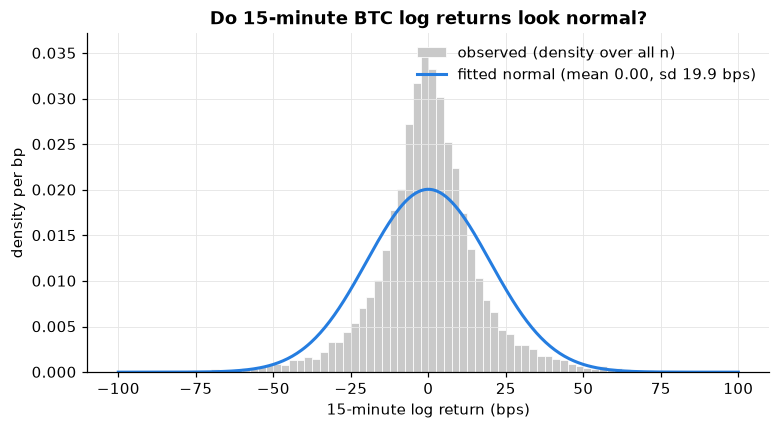

*BTCUSDT, 2026-05-01 to 2026-10-31, n = 17,647 windows. Visible range ±100 bps; 61 observations (0.35%) lie outside it and are included in the density scaling.*

In [6]:
mu, sd = r.mean(), r.std(ddof=1)
lim = 100
fig, ax = plt.subplots(figsize=(8, 4))
inside = r[np.abs(r) <= lim]
bw = 2.5   # bin width in bps; heights = count / (n_all * bw), so the area over the visible range is the share inside it
ax.hist(inside, bins=np.arange(-lim, lim + bw, bw), color="#c9c9c9", edgecolor="white", linewidth=0.5,
        label="observed (density over all n)", weights=np.full(len(inside), 1 / (len(r) * bw)))
x = np.linspace(-lim, lim, 400)
ax.plot(x, stats.norm.pdf(x, mu, sd), color=COLORS["normal"], label=f"fitted normal (mean {mu:.2f}, sd {sd:.1f} bps)")
n_out = int((np.abs(r) > lim).sum())
ax.set(xlabel="15-minute log return (bps)", ylabel="density per bp",
       title="Do 15-minute BTC log returns look normal?")
ax.legend(frameon=False)
plt.show()
show(f"*BTCUSDT, {utc(df.t_decision.min()):%Y-%m-%d} to {utc(df.t_decision.max()):%Y-%m-%d}, n = {len(r):,} windows. "
     f"Visible range ±{lim} bps; {n_out} observations ({n_out/len(r):.2%}) lie outside it and are included in the density scaling.*")

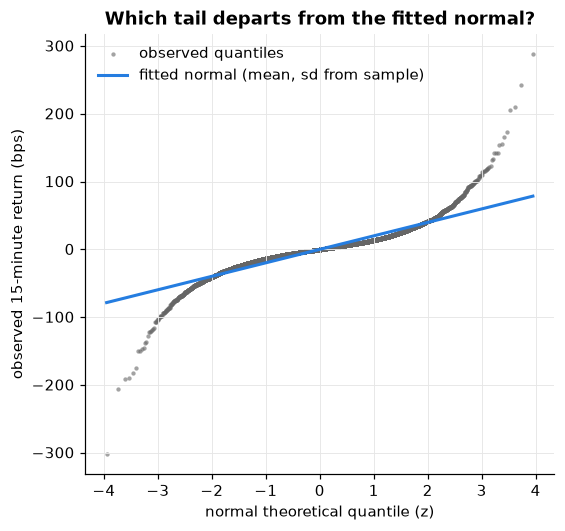

*At z = −3 the sample quantile is -102.7 bps vs -59.6 bps under the fit; at z = +3 it is 110.3 vs 59.7 bps. Most extreme: -302 bps and +289 bps.*

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.2))
(osm, osr), _ = stats.probplot(r, dist="norm")
ax.scatter(osm, osr, s=8, color=COLORS["data"], alpha=0.6, linewidths=0, label="observed quantiles")
ax.plot(osm, mu + sd * osm, color=COLORS["normal"], label="fitted normal (mean, sd from sample)")
ax.set(xlabel="normal theoretical quantile (z)", ylabel="observed 15-minute return (bps)",
       title="Which tail departs from the fitted normal?")
ax.legend(frameon=False, loc="upper left")
plt.show()
z = np.array([-3, 3]); qq = np.quantile(r, stats.norm.cdf(z))
show(f"*At z = −3 the sample quantile is {qq[0]:.1f} bps vs {mu+sd*z[0]:.1f} bps under the fit; at z = +3 it is {qq[1]:.1f} vs {mu+sd*z[1]:.1f} bps. "
     f"Most extreme: {r.min():.0f} bps and +{r.max():.0f} bps.*")

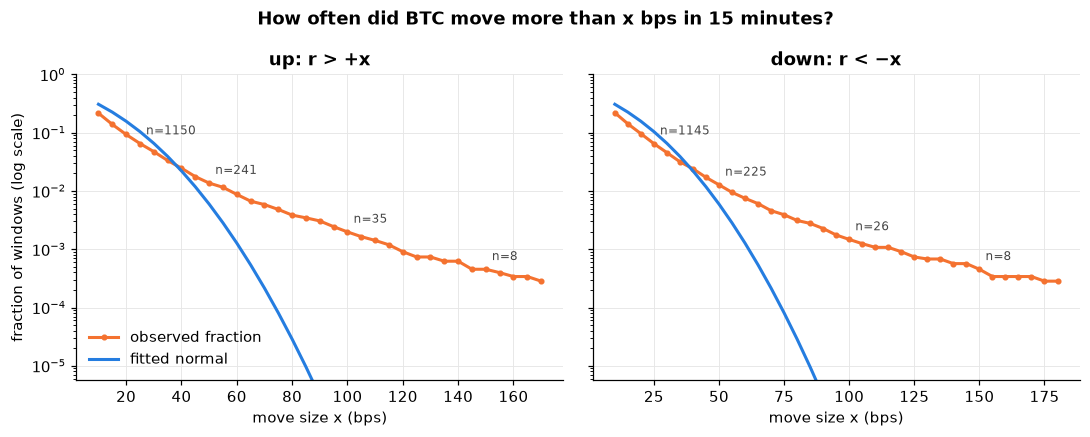

*Only thresholds with at least 5 observed windows are drawn (n = 17,647). Labels show the raw window counts. The y-axis stops at 0.1/n; below that the normal curve continues off the chart.*

In [8]:
thr = np.arange(10, 201, 5)
up = np.array([(r > t).sum() for t in thr]); dn = np.array([(r < -t).sum() for t in thr])
keep = (up >= 5) | (dn >= 5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, cnt, side, sign in [(axes[0], up, "up", 1), (axes[1], dn, "down", -1)]:
    m = cnt >= 5
    ax.plot(thr[m], cnt[m] / len(r), color=COLORS["empirical"], marker="o", ms=3, label="observed fraction")
    normp = stats.norm.sf(thr, mu, sd) if sign > 0 else stats.norm.cdf(-thr, mu, sd)
    ax.plot(thr[m], normp[m], color=COLORS["normal"], label="fitted normal")
    for t in (25, 50, 100, 150):
        i = np.where(thr == t)[0][0]
        if m[i]: ax.annotate(f"n={cnt[i]}", (t, cnt[i] / len(r)), textcoords="offset points", xytext=(4, 6), fontsize=8, color="#444")
    ax.set_yscale("log"); ax.set_ylim(0.1 / len(r), 1); ax.set_xlabel(f"move size x (bps)")
    ax.set_title(f"{side}: r {'> +x' if sign>0 else '< −x'}")
axes[0].set_ylabel("fraction of windows (log scale)"); axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("How often did BTC move more than x bps in 15 minutes?", fontweight="bold", fontsize=11.5)
plt.tight_layout(); plt.show()
show(f"*Only thresholds with at least 5 observed windows are drawn (n = {len(r):,}). Labels show the raw window counts. The y-axis stops at 0.1/n; below that the normal curve continues off the chart.*")

In [9]:
rows = []
for t in (25, 50, 75, 100, 150):
    rows.append({"x (bps)": t, "observed r > +x": int((r > t).sum()), "normal expects": round(len(r) * stats.norm.sf(t, mu, sd), 1),
                 "observed r < −x": int((r < -t).sum()), "normal expects ": round(len(r) * stats.norm.cdf(-t, mu, sd), 1)})
tail_tbl = pd.DataFrame(rows); tail_tbl

,x (bps),observed r > +x,normal expects,observed r < −x,normal expects
0,25,1150,1841.4,1145,1840.4
1,50,241,105.2,225,105.1
2,75,85,1.4,69,1.4
3,100,35,0.0,26,0.0
4,150,8,0.0,8,0.0


**Judgment call: is the skew real or a handful of windows?** The table below recomputes the moments by calendar month and lists the most extreme windows. The last block is a **sensitivity check only**: it drops the 5 largest |r| windows. Every other result in this notebook uses all observations.

In [10]:
df["month"] = utc(df.t_decision).dt.strftime("%Y-%m")
sub = df.groupby("month")["r_bps"].agg(n="size", std_bps=lambda x: x.std(ddof=1),
                                         skew=lambda x: stats.skew(x, bias=False), excess_kurt=lambda x: stats.kurtosis(x, bias=False)).round(2)
display(sub)
ext = df.reindex(df["r_bps"].abs().sort_values(ascending=False).index).head(8)
display(pd.DataFrame({"window start (UTC)": utc(ext.t_decision), "S": ext.s_start, "S_end": ext.s_end, "r (bps)": ext.r_bps.round(1)}).reset_index(drop=True))
top5 = df["r_bps"].abs().nlargest(5).index
r_ex = df.drop(top5)["r_bps"]
sens = pd.DataFrame({"skewness": [stats.skew(r, bias=False), stats.skew(r_ex, bias=False)],
                     "excess kurtosis": [stats.kurtosis(r, bias=False), stats.kurtosis(r_ex, bias=False)]},
                    index=["all windows", "SENSITIVITY: without 5 largest |r|"]).round(3)
sens

,n,std_bps,skew,excess_kurt
month,,,,
2026-05,2959,16.28,-0.13,9.31
2026-06,2880,28.24,-0.04,12.45
2026-07,2976,17.65,0.28,5.37
2026-08,2976,19.10,1.54,25.33
2026-09,2880,18.77,-0.06,14.63
2026-10,2976,17.06,-0.41,13.63


,window start (UTC),S,S_end,r (bps)
0,2026-06-25 13:45:00+00:00,60077.99,58290.17,-302.1
1,2026-06-07 22:00:00+00:00,61778.41,63586.98,288.5
2,2026-08-19 15:15:00+00:00,66654.00,68291.89,242.8
3,2026-08-20 08:00:00+00:00,69816.45,71300.01,210.3
4,2026-09-04 12:30:00+00:00,81340.00,79686.00,-205.4
5,2026-08-21 08:45:00+00:00,77647.34,79258.03,205.3
6,2026-06-25 13:30:00+00:00,61240.01,60077.99,-191.6
7,2026-10-29 20:30:00+00:00,80395.81,78884.52,-189.8


,skewness,excess kurtosis
all windows,0.160,16.948
SENSITIVITY: without 5 largest |r|,0.086,9.956


In [11]:
lo, hi = sub["skew"].idxmin(), sub["skew"].idxmax()
show(f"Monthly skew ranges from {sub.loc[lo,'skew']:.2f} ({lo}) to {sub.loc[hi,'skew']:.2f} ({hi}). Full-sample skew is "
     f"{stats.skew(r, bias=False):.3f}; without the 5 largest moves it is {stats.skew(r_ex, bias=False):.3f}. "
     f"Excess kurtosis is positive in every month (min {sub['excess_kurt'].min():.1f}).")

Monthly skew ranges from -0.41 (2026-10) to 1.54 (2026-08). Full-sample skew is 0.160; without the 5 largest moves it is 0.086. Excess kurtosis is positive in every month (min 5.4).

**Questions to answer after looking at the figures** (my answers):
1. Which tail of the Q–Q plot departs further from the normal line, and is that consistent with the up/down exceedance counts at 50 and 100 bps?
   *Answer:*
2. Does the monthly table support "BTC 15-minute returns are positively skewed", or does one month carry the sign?
   *Answer:*
3. At ±25 bps, does the normal overstate or understate how often BTC clears the level, and why does a peaked center do that?
   *Answer:*

## 3. Forecasting setup

**Pricing relationship.** At decision time $T$ BTC is at $S$. For a level $K$:
"BTC finishes the window above $K$" $\iff S_{end} > K \iff r > \log(K/S)$.
So every forecaster only has to say how likely the next 15-minute log return is to exceed $m = \log(K/S)$. The inequality is **strict** everywhere in the spot experiment.

**Strikes.** Five hypothetical strikes per window at $k \in \{-50,-25,0,+25,+50\}$ **log-return** bps, with $K = S\,e^{k/10^4}$ (so $m = k/10^4$ exactly). These are synthetic. The Kalshi section uses each contract's listed strike.

**Features** (known at $T$, built only from candles that closed by $T$):
`rv_60` and `rv_240` are the square root of the sum of squared 1-minute log returns over the last 60 or 240 minutes, scaled to a 15-minute horizon. `r_lag1` and `r_lag2` are the previous two 15-minute returns. Rolling windows are trailing and require every minute.

**Splits** (by decision time; every strike of a window stays in the window's block): train May–Aug, validation September, test October. Rows whose label resolves after the next block starts are purged.

In [12]:
df, n_purged = chronological_split(df, VAL_START, TEST_START)
split_tbl = df.groupby("split").agg(first_T=("t_decision", "min"), last_T=("t_decision", "max"), windows=("t_decision", "size"))
split_tbl = split_tbl.loc[["train", "val", "test"]]
split_tbl["last label resolves"] = utc(split_tbl.last_T + 900)
split_tbl["first_T"], split_tbl["last_T"] = utc(split_tbl.first_T), utc(split_tbl.last_T)
split_tbl["rows (x5 strikes)"] = split_tbl.windows * len(STRIKES_BPS)
assert (df.loc[df.split == "train", "t_decision"] + 900 <= VAL_START).all()
assert (df.loc[df.split == "val", "t_decision"] + 900 <= TEST_START).all()
display(split_tbl)
show(f"Purged for label overlap: {n_purged} (windows are aligned to whole days, so none overlap).")

,first_T,last_T,windows,last label resolves,rows (x5 strikes)
split,,,,,
train,2026-05-01 04:15:00+00:00,2026-08-31 23:45:00+00:00,11791,2026-09-01 00:00:00+00:00,58955
val,2026-09-01 00:00:00+00:00,2026-09-30 23:45:00+00:00,2880,2026-10-01 00:00:00+00:00,14400
test,2026-10-01 00:00:00+00:00,2026-10-31 23:45:00+00:00,2976,2026-11-01 00:00:00+00:00,14880


Purged for label overlap: 0 (windows are aligned to whole days, so none overlap).

In [13]:
row = df[df.split == "test"].iloc[0]
T = int(row.t_decision)
pd.DataFrame({
  "item": ["decision time T", "rv_60 uses candles opening", "rv_240 uses candles opening", "r_lag1 uses closes of candles opening",
           "r_lag2 uses closes of candles opening", "latest input known at", "label uses close of candle opening (known at)"],
  "UTC": [utc(T), f"{utc(T-60*60)} .. {utc(T-60)}", f"{utc(T-240*60)} .. {utc(T-60)}", f"{utc(T-960)} and {utc(T-60)}",
          f"{utc(T-1860)} and {utc(T-960)}", utc(row.feature_known_at), f"{utc(T+840)} ({utc(T+900)})"]})

,item,UTC
0,decision time T,2026-10-01 00:00:00+00:00
1,rv_60 uses candles opening,2026-09-30 23:00:00+00:00 .. 2026-09-30 23:59:...
2,rv_240 uses candles opening,2026-09-30 20:00:00+00:00 .. 2026-09-30 23:59:...
3,r_lag1 uses closes of candles opening,2026-09-30 23:44:00+00:00 and 2026-09-30 23:59...
4,r_lag2 uses closes of candles opening,2026-09-30 23:29:00+00:00 and 2026-09-30 23:44...
5,latest input known at,2026-10-01 00:00:00+00:00
6,label uses close of candle opening (known at),2026-10-01 00:14:00+00:00 (2026-10-01 00:15:00...


## 4. Normal vs empirical on held-out data

- **A. Normal:** fit $\hat\mu, \hat\sigma$ on training returns, $P(r>m) = 1-\Phi((m-\hat\mu)/\hat\sigma)$.
- **B. Empirical:** $P(r>m)$ = fraction of training returns strictly above $m$.

Both are fitted on the 4 training months only and give the same probability for every window at a given strike.
**Scoring convention (all models):** before log loss, probabilities are clipped to $[10^{-4}, 1-10^{-4}]$, so an empirical 0 or 1 costs at most $-\log(10^{-4}) \approx 9.2$ nats. The Brier score uses unclipped probabilities.

In [14]:
tr_r = df.loc[df.split == "train", "r"].to_numpy()
normal, emp = NormalModel().fit(tr_r), EmpiricalModel().fit(tr_r)
S = stack_strikes(df)
S["m"] = S["k_bps"] / BPS
S["normal"] = normal.prob_above(S["m"])
S["empirical"] = emp.prob_above(S["m"])
S["day"] = utc(S.t_decision).dt.date
strike_tbl = pd.DataFrame({"strike k (log bps)": STRIKES_BPS,
                           "P normal": normal.prob_above(np.array(STRIKES_BPS) / BPS),
                           "P empirical": emp.prob_above(np.array(STRIKES_BPS) / BPS),
                           "training windows with r > k": emp.count_above(np.array(STRIKES_BPS) / BPS)})
strike_tbl["difference (emp − normal)"] = strike_tbl["P empirical"] - strike_tbl["P normal"]
show(f"Training fit: mean = {normal.mu*BPS:.3f} bps, sd = {normal.sigma*BPS:.2f} bps, n = {normal.n:,} windows.")
strike_tbl.round(4)

Training fit: mean = 0.016 bps, sd = 20.79 bps, n = 11,791 windows.

,strike k (log bps),P normal,P empirical,training windows with r > k,difference (emp − normal)
0,-50,0.9919,0.9858,11624,-0.0061
1,-25,0.8856,0.9306,10973,0.0451
2,0,0.5003,0.4916,5796,-0.0087
3,25,0.1147,0.0706,832,-0.0442
4,50,0.0081,0.0160,189,0.0079


In [15]:
k_star = int(strike_tbl.loc[strike_tbl["difference (emp − normal)"].abs().idxmax(), "strike k (log bps)"])
ex = S[(S.split == "test") & (S.k_bps == k_star)].iloc[0]          # first held-out window, not hand-picked
cnt = int(emp.count_above(k_star / BPS))
pd.DataFrame({"": ["decision time T (UTC)", "expiry (UTC)", "time to expiry", "S (BTCUSDT close at T)", f"strike K = S·exp({k_star}/10⁴)",
                   "required move log(K/S)", "P normal", "P empirical", f"training windows with r > {k_star} bps", "S_end", "realized r", "outcome (S_end > K)"],
              "value": [utc(ex.t_decision), utc(ex.t_label), "15 min", f"{ex.s_start:,.2f}", f"{ex.K:,.2f}", f"{ex.m*BPS:.1f} bps",
                        f"{ex.normal:.4f}", f"{ex.empirical:.4f}", f"{cnt:,} of {emp.n:,}", f"{ex.s_end:,.2f}", f"{ex.r*BPS:.2f} bps", int(ex.y)]})

,,value
0,decision time T (UTC),2026-10-01 00:00:00+00:00
1,expiry (UTC),2026-10-01 00:15:00+00:00
2,time to expiry,15 min
3,S (BTCUSDT close at T),"83,623.60"
4,strike K = S·exp(-25/10⁴),"83,414.80"
5,required move log(K/S),-25.0 bps
6,P normal,0.8856
7,P empirical,0.9306
8,training windows with r > -25 bps,"10,973 of 11,791"
9,S_end,"83,509.05"


In [16]:
z_star = (k_star / BPS - normal.mu) / normal.sigma
show(f"**Why they differ at k = {k_star:+d} bps.** The normal uses one sd ({normal.sigma*BPS:.1f} bps) for the whole distribution. "
     f"That sd is inflated by the rare large moves, so a {abs(k_star)} bp move is only {abs(z_star):.2f} sd away and the normal assigns it "
     f"{strike_tbl.set_index('strike k (log bps)').loc[k_star,'P normal']:.3f}. The empirical model just counts: {cnt:,} of {emp.n:,} training "
     f"windows cleared it ({cnt/emp.n:.3f}). The sample is more peaked than the normal, so moderate moves are rarer than the fit implies. "
     f"Large moves are more common, which is why the sign of the difference flips at ±50 bps (table above).")

**Why they differ at k = -25 bps.** The normal uses one sd (20.8 bps) for the whole distribution. That sd is inflated by the rare large moves, so a 25 bp move is only 1.20 sd away and the normal assigns it 0.886. The empirical model just counts: 10,973 of 11,791 training windows cleared it (0.931). The sample is more peaked than the normal, so moderate moves are rarer than the fit implies. Large moves are more common, which is why the sign of the difference flips at ±50 bps (table above).

In [17]:
TE = S[S.split == "test"].copy()
base = score_table(TE, ["normal", "empirical"]).set_index("model")[["n", "brier", "log_loss"]]
by_k = score_table(TE, ["normal", "empirical"], by="k_bps").pivot(index="group", columns="model", values=["brier", "log_loss"])
by_k.index.name = "strike k"
display(base.round(5)); display(by_k.round(5))

,n,brier,log_loss
model,,,
normal,14880,0.07407,0.24823
empirical,14880,0.07255,0.23992


brier           log_loss         
model    empirical   normal empirical   normal
strike k                                      
-50        0.00967  0.00965   0.05561  0.05499
-25        0.04909  0.05274   0.20538  0.22673
 0         0.24996  0.25000   0.69306  0.69316
 25        0.04596  0.04993   0.19619  0.21936
 50        0.00806  0.00800   0.04936  0.04691

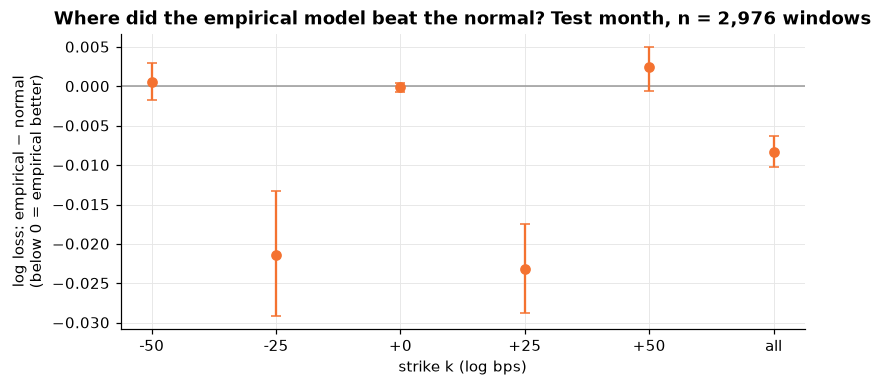

*95% intervals: percentile bootstrap over whole calendar days of the test month (2,000 resamples). All strikes of a window stay together, so five strikes of one realized move are not counted as five independent observations.*

,metric,strike,empirical − normal,95% CI low,95% CI high
0,log_loss,-50,0.00062,-0.00167,0.00291
1,log_loss,-25,-0.02135,-0.02911,-0.01322
2,log_loss,0,-0.00009,-0.00068,0.00048
3,log_loss,25,-0.02317,-0.02874,-0.01742
4,log_loss,50,0.00246,-0.00056,0.00501
5,log_loss,all,-0.00831,-0.01028,-0.00631
6,brier,-50,0.00002,-0.00003,0.00007
7,brier,-25,-0.00365,-0.00492,-0.00232
8,brier,0,-0.00005,-0.00034,0.00024
9,brier,25,-0.00397,-0.00489,-0.00302


In [18]:
rows = []
for metric in ["log_loss", "brier"]:
    for k in STRIKES_BPS + ["all"]:
        d = TE if k == "all" else TE[TE.k_bps == k]
        est, lo_, hi_ = block_bootstrap_diff(d, "empirical", "normal", metric)
        rows.append({"metric": metric, "strike": k, "empirical − normal": est, "95% CI low": lo_, "95% CI high": hi_})
ci = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
c = ci[ci.metric == "log_loss"].reset_index(drop=True)
xs = np.arange(len(c))
ax.axhline(0, color="#999", lw=1)
ax.errorbar(xs, c["empirical − normal"], yerr=[c["empirical − normal"] - c["95% CI low"], c["95% CI high"] - c["empirical − normal"]],
            fmt="o", color=COLORS["empirical"], ms=6, capsize=3, lw=1.5)
ax.set_xticks(xs, [f"{k:+d}" if k != "all" else "all" for k in c.strike])
ax.set(xlabel="strike k (log bps)", ylabel="log loss: empirical − normal\n(below 0 = empirical better)",
       title=f"Where did the empirical model beat the normal? Test month, n = {TE.t_decision.nunique():,} windows")
plt.tight_layout(); plt.show()
show("*95% intervals: percentile bootstrap over whole calendar days of the test month (2,000 resamples). All strikes of a window stay together, "
     "so five strikes of one realized move are not counted as five independent observations.*")
ci.round(5)

In [19]:
a = ci[(ci.metric == "log_loss") & (ci.strike == "all")].iloc[0]
b = ci[(ci.metric == "brier") & (ci.strike == "all")].iloc[0]
show(f"**Result (test, all strikes).** Log loss: normal {base.loc['normal','log_loss']:.4f}, empirical {base.loc['empirical','log_loss']:.4f} "
     f"(difference {a['empirical − normal']:+.4f}, 95% CI [{a['95% CI low']:+.4f}, {a['95% CI high']:+.4f}]). "
     f"Brier: normal {base.loc['normal','brier']:.5f}, empirical {base.loc['empirical','brier']:.5f} "
     f"(difference {b['empirical − normal']:+.5f}, CI [{b['95% CI low']:+.5f}, {b['95% CI high']:+.5f}]).")

**Result (test, all strikes).** Log loss: normal 0.2482, empirical 0.2399 (difference -0.0083, 95% CI [-0.0103, -0.0063]). Brier: normal 0.07407, empirical 0.07255 (difference -0.00152, CI [-0.00190, -0.00112]).

## 5. Extension: does conditioning on recent volatility help?

A and B ignore the fact that volatility clusters. Two conditional models, each with one comparison it has to win:

- **C. Logistic regression** (scikit-learn `Pipeline`: `StandardScaler` → `LogisticRegression`, so scaling is fitted on training rows only). It predicts $1\{r>m\}$ from the strike and trailing features. Three specs are compared on **validation** log loss. **Comparison to win: beat the empirical model** (the unconditional baseline that uses the same training returns without a shape assumption) on test log loss.
- **D. PyTorch conditional Gaussian.** 4 inputs → 16 tanh units → (mean, softplus scale), trained with Gaussian NLL on the return itself, seeded, with early stopping on validation NLL. $P(r>m) = 1-\Phi((m-\mu_t)/\sigma_t)$. **Comparison to win: beat the unconditional normal**, the same distribution family with constant $\sigma$, on test log loss. This asks whether time-varying volatility explains some of the fat tails.

*Disclosure:* an earlier draft trained the net with lr = 0.001 and a 300-epoch cap. Validation loss was still improving at the cap (best epoch 298 of 300). I saw that run's test scores, then raised the cap to 1,000 epochs (patience 30) and let validation NLL choose between lr 0.003 and 0.01. The other models and the splits were not changed after any test result was seen. In the draft run the net's test log loss was 0.2339, versus 0.2335 now.

In [20]:
TR, VA = S[S.split == "train"], S[S.split == "val"]
sel = []
fits = {}
for spec in ["base", "interaction", "vol_scaled"]:
    Xtr, names = logistic_design(TR, spec); Xva, _ = logistic_design(VA, spec)
    pipe = logistic_pipeline().fit(Xtr, TR.y)
    fits[spec] = (pipe, names)
    pva = pipe.predict_proba(Xva)[:, 1]
    sel.append({"spec": spec, "features": ", ".join(names), "val log loss": log_loss(pva, VA.y), "val Brier": brier(pva, VA.y)})
sel = pd.DataFrame(sel).sort_values("val log loss")
best_spec = sel.iloc[0]["spec"]
display(sel.round(5))
pipe, names = fits[best_spec]
coef = pd.DataFrame({"feature (standardized)": names, "coefficient": pipe.named_steps["logit"].coef_[0]}).round(3)
show(f"Selected on validation: **{best_spec}**. Coefficients are per training-sd of each input:")
coef

,spec,features,val log loss,val Brier
1,interaction,"k, rv_60, rv_240, r_lag1, r_lag2, k_x_rv60",0.24562,0.07611
2,vol_scaled,"k, k_over_rv240, r_lag1, r_lag2",0.24600,0.07617
0,base,"k, rv_60, rv_240, r_lag1, r_lag2",0.25405,0.07688


Selected on validation: **interaction**. Coefficients are per training-sd of each input:

,feature (standardized),coefficient
0,k,-4.678
1,rv_60,0.060
2,rv_240,-0.045
3,r_lag1,-0.037
4,r_lag2,-0.014
5,k_x_rv60,1.213


In [21]:
S["logistic"] = pipe.predict_proba(logistic_design(S, best_spec)[0])[:, 1]

# --- PyTorch model (Section 4 does not depend on this cell) ---
W = df.reset_index(drop=True)
Xw = net_inputs(W)
trm, vam = (W.split == "train").to_numpy(), (W.split == "val").to_numpy()
runs = {lr: fit_gaussian_net(Xw[trm], W.r[trm], Xw[vam], W.r[vam], lr=lr, seed=0) for lr in (3e-3, 1e-2)}
val_nll = {lr: min(h[2] for h in hh) for lr, (_, hh) in runs.items()}
best_lr = min(val_nll, key=val_nll.get)
predict, hist = runs[best_lr]
mu_t, sig_t = predict(Xw)                       # bps
W["mu_t"], W["sig_t"] = mu_t, sig_t
S = S.merge(W[["t_decision", "mu_t", "sig_t"]], on="t_decision", how="left")
S["torch"] = stats.norm.sf((S["k_bps"] - S["mu_t"]) / S["sig_t"])
best_ep = int(np.argmin([h[2] for h in hist]))
te = W.split == "test"
nll_norm = -stats.norm.logpdf(W.r_bps[te], normal.mu * BPS, normal.sigma * BPS).mean()
nll_net = -stats.norm.logpdf(W.r_bps[te], W.mu_t[te], W.sig_t[te]).mean()
show(f"Learning rate chosen on validation NLL: {best_lr} (candidates: " + ", ".join(f"{k}: {v:.4f}" for k, v in val_nll.items()) + "). "
     f"Early stopping kept epoch {best_ep} of {len(hist)} run (validation NLL {hist[best_ep][2]:.4f}). On test returns, mean Gaussian NLL "
     f"(nats per window, returns in bps): constant-σ normal {nll_norm:.4f}, conditional net {nll_net:.4f}. "
     f"Predicted σ on test ranges {W.sig_t[te].min():.1f}–{W.sig_t[te].max():.1f} bps (median {W.sig_t[te].median():.1f}).")

Learning rate chosen on validation NLL: 0.01 (candidates: 0.003: 4.2100, 0.01: 4.2079). Early stopping kept epoch 166 of 197 run (validation NLL 4.2079). On test returns, mean Gaussian NLL (nats per window, returns in bps): constant-σ normal 4.2901, conditional net 4.1132. Predicted σ on test ranges 4.2–29.3 bps (median 15.3).

In [22]:
MODELS = ["normal", "empirical", "logistic", "torch"]
TE = S[S.split == "test"].copy()
overall = score_table(TE, MODELS).set_index("model")[["n", "brier", "log_loss"]]
earn = []
for model, baseline in [("empirical", "normal"), ("logistic", "empirical"), ("torch", "normal")]:
    for metric in ["log_loss", "brier"]:
        est, l, h = block_bootstrap_diff(TE, model, baseline, metric)
        earn.append({"comparison": f"{model} − {baseline}", "metric": metric, "difference": est, "95% CI low": l, "95% CI high": h,
                     "better on test": model if h < 0 else (baseline if l > 0 else "no clear winner")})
earn = pd.DataFrame(earn)
mono = pd.DataFrame({"model": MODELS, "decision times where P rises with strike": [monotonicity_violations(TE, m) for m in MODELS],
                     "test decision times": TE.t_decision.nunique()})
display(overall.round(5)); display(earn.round(5)); mono

,n,brier,log_loss
model,,,
normal,14880,0.07407,0.24823
empirical,14880,0.07255,0.23992
logistic,14880,0.07182,0.23266
torch,14880,0.07190,0.23351


,comparison,metric,difference,95% CI low,95% CI high,better on test
0,empirical − normal,log_loss,-0.00831,-0.01028,-0.00631,empirical
1,empirical − normal,brier,-0.00152,-0.00190,-0.00112,empirical
2,logistic − empirical,log_loss,-0.00726,-0.00945,-0.00539,logistic
3,logistic − empirical,brier,-0.00073,-0.00112,-0.00045,logistic
4,torch − normal,log_loss,-0.01472,-0.02001,-0.00978,torch
5,torch − normal,brier,-0.00216,-0.00272,-0.00162,torch


,model,decision times where P rises with strike,test decision times
0,normal,0,2976
1,empirical,0,2976
2,logistic,0,2976
3,torch,0,2976


In [23]:
byk = score_table(TE, MODELS, by="k_bps").pivot(index="group", columns="model", values="log_loss")[MODELS]
byk.index.name = "strike k"; byk.columns.name = "log loss"
display(byk.round(4))
best = {m: overall[m].idxmin() for m in ["brier", "log_loss"]}
show(f"Best on test: Brier → **{best['brier']}** ({overall.loc[best['brier'],'brier']:.5f}), "
     f"log loss → **{best['log_loss']}** ({overall.loc[best['log_loss'],'log_loss']:.4f}). "
     f"Spread between best and worst log loss: {overall.log_loss.max()-overall.log_loss.min():.4f} nats per row.")

log loss,normal,empirical,logistic,torch
strike k,,,,
-50,0.0550,0.0556,0.0532,0.0560
-25,0.2267,0.2054,0.1938,0.1934
0,0.6932,0.6931,0.6932,0.6925
25,0.2194,0.1962,0.1806,0.1832
50,0.0469,0.0494,0.0425,0.0423


Best on test: Brier → **logistic** (0.07182), log loss → **logistic** (0.2327). Spread between best and worst log loss: 0.0156 nats per row.

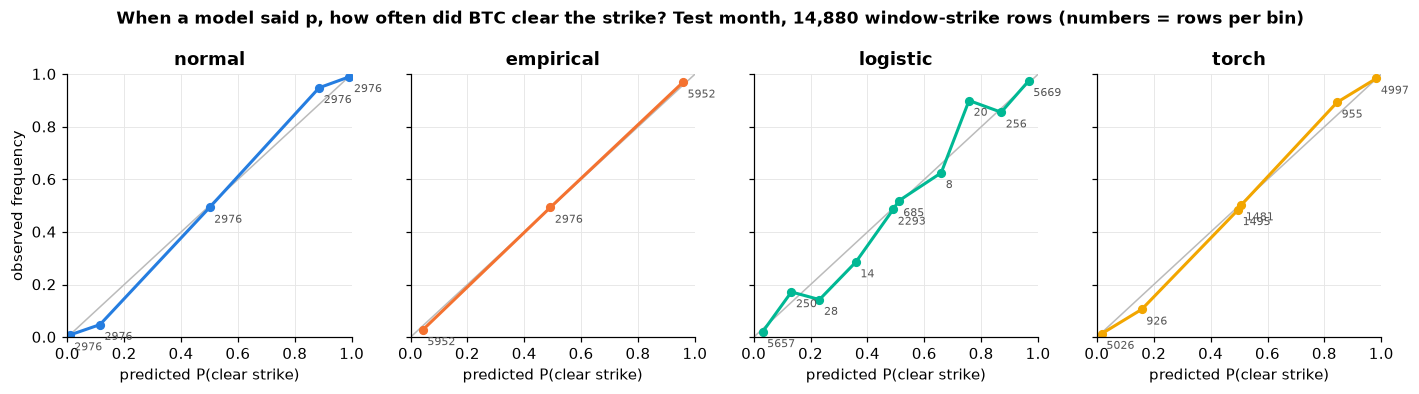

*Unconditional models put every row of a strike in the same bin, so they show at most five points.*

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, MODELS):
    rel = reliability(TE[m], TE.y)
    ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
    ax.plot(rel.mean_pred, rel.obs_freq, marker="o", ms=5, color=COLORS[m])
    for _, rr in rel.iterrows():
        ax.annotate(f"{rr.n}", (rr.mean_pred, rr.obs_freq), textcoords="offset points", xytext=(3, -10), fontsize=7, color="#555")
    ax.set_title(m); ax.set_xlabel("predicted P(clear strike)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0].set_ylabel("observed frequency")
fig.suptitle(f"When a model said p, how often did BTC clear the strike? Test month, {len(TE):,} window-strike rows (numbers = rows per bin)",
             fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
show("*Unconditional models put every row of a strike in the same bin, so they show at most five points.*")

### Result table (generated)

In [25]:
res = overall.copy()
res["log loss vs normal"] = res.log_loss - res.loc["normal", "log_loss"]
res["Brier vs normal"] = res.brier - res.loc["normal", "brier"]
res["monotonicity violations"] = mono.set_index("model").iloc[:, 0]
res.index.name = f"test {utc(TE.t_decision.min()):%Y-%m-%d}..{utc(TE.t_decision.max()):%Y-%m-%d}"
res.round(5)

,n,brier,log_loss,log loss vs normal,Brier vs normal,monotonicity violations
test 2026-10-01..2026-10-31,,,,,,
normal,14880,0.07407,0.24823,0.00000,0.00000,0
empirical,14880,0.07255,0.23992,-0.00831,-0.00152,0
logistic,14880,0.07182,0.23266,-0.01557,-0.00225,0
torch,14880,0.07190,0.23351,-0.01472,-0.00216,0


### My interpretation
*(to fill in after running)*

- Did the empirical model beat the normal model? At which strikes, and by how much relative to the CI?

- Where did volatility conditioning (logistic, PyTorch) help or hurt?

- Are the differences large enough to care about?

## 6. What does the public Kalshi data let me test?

**Contract.** Series `KXBTC15M`, "BTC price up in next 15 mins?". The terms below come from the cached public API responses (`btc_tails/kalshi.py`).

In [26]:
meta = json.loads((RAW_KALSHI / "_series_meta.json").read_text())
files = sorted(p for p in RAW_KALSHI.glob("KXBTC15M-*.json"))
recs = [json.loads(p.read_text()) for p in files]
sample = next(x for x in recs if x["market"])["market"]
ser = meta["series"]["series"]
terms = pd.DataFrame({"field": ["series", "sample ticker", "window", "strike (floor_strike)", "YES condition (rules_primary)", "strike_type",
                                "settlement source", "settlement value", "fee_type / fee_multiplier (series metadata, retrieved)",
                                "series fee-change history (show_historical=true)", "historical archive cutoff (market_settled_ts)"],
  "value": [ser["ticker"], sample["ticker"], f"{sample['open_time']} → {sample['close_time']}", sample["floor_strike"], sample["rules_primary"],
            sample["strike_type"], ser["settlement_sources"][0]["name"] + " BRTI", "simple average of 60 one-second BRTI values before close (rules_secondary)",
            f"{ser['fee_type']} / {ser['fee_multiplier']} (as of {meta['retrieved_utc']})", str(meta["fee_changes"]["series_fee_change_arr"]),
            meta["historical_cutoff"]["market_settled_ts"]]})
with pd.option_context("display.max_colwidth", 200): display(terms)

,field,value
0,series,KXBTC15M
1,sample ticker,KXBTC15M-26OCT010000-00
2,window,2026-10-01T03:45:00Z → 2026-10-01T04:00:00Z
3,strike (floor_strike),83663.77
4,YES condition (rules_primary),"If the simple average of the sixty seconds of CF Benchmarks' BRTI before 12:00 AM EDT on Oct 1, 2026 is at least the simple average of the sixty seconds of CF Benchmarks' BRTI before 11:45 PM EDT ..."
5,strike_type,greater_or_equal
6,settlement source,CF Benchmarks BRTI
7,settlement value,simple average of 60 one-second BRTI values before close (rules_secondary)
8,"fee_type / fee_multiplier (series metadata, retrieved)",quadratic / 1 (as of 2026-11-26T17:34:14+00:00)
9,series fee-change history (show_historical=true),[]


**What this means for the comparison.**
- The strike is the 60-second BRTI average *before the window opens*, so it is known at the open. The event is "closing average ≥ opening average": effectively a 0 bp strike over 15 minutes, with **≥** rather than the spot experiment's strict >.
- Settlement uses BRTI (a USD index built from several exchanges) averaged over a minute, not a Binance BTCUSDT point close. I measure how well Binance reproduces the outcome below.
- **Decision time = open + 1 minute.** Quotes only exist after the open. The first 1-minute quote candle ends at open+1 min, and its `close` is the best YES bid and ask at that instant. Using it at the open would look ahead, so the model also decides at open+1 min with 14 minutes left.
- **Available historical fields per market:** metadata (strike, result, expiration value, volume) and 1-minute candles of YES bid OHLC, YES ask OHLC and trade price OHLC. **Not available:** quote sizes or depth, order-book history, and my own fills. The fee schedule PDF referenced by the API (`kalshi.com/docs/kalshi-fee-schedule.pdf`) returned HTTP 429 to automated requests, so I could not verify which fee applied in October.

In [27]:
rows = []
for x in recs:
    m = x["market"]; T = x["window_open_utc"]
    row = {"t_decision_open": T, "ticker": m["ticker"] if m else None, "found": m is not None, "source": x["source"]}
    if m:
        row.update(floor_strike=m.get("floor_strike"), result=m.get("result"), volume=float(m.get("volume_fp") or m.get("volume") or 0))
        c = next((c for c in x["candlesticks"] if c["end_period_ts"] == T + 60), None)
        if c:
            g = lambda d, k: float(d.get(k + "_dollars", d.get(k)) or np.nan)
            row.update(quote_ts=c["end_period_ts"], bid=g(c["yes_bid"], "close"), ask=g(c["yes_ask"], "close"),
                       minute_volume=float(c.get("volume_fp", c.get("volume")) or 0))
    rows.append(row)
K = pd.DataFrame(rows)
K["has_quote"] = K.bid.gt(0) & K.ask.lt(1) & K.ask.gt(K.bid)
K["mid"] = (K.bid + K.ask) / 2
K["spread"] = K.ask - K.bid

# Binance proxies (minute candles): S at open+1min, opening/closing 60-second averages approximated by the mean of OHLC
mins = load_minutes(con).set_index("ts_open")
typ = mins[["open", "high", "low", "close"]].mean(axis=1)
K["S_dec"] = mins["close"].reindex(K.t_decision_open).to_numpy()            # candle T closes at T+60
K["K_proxy"] = typ.reindex(K.t_decision_open - 60).to_numpy()               # minute before the open
K["end_proxy"] = typ.reindex(K.t_decision_open + 840).to_numpy()            # last minute of the window
K["m"] = np.log(K.K_proxy / K.S_dec)
K["y"] = (K.result == "yes").astype(float)
K["basis_bps"] = np.log(K.floor_strike / K.K_proxy) * BPS
in_test = K.t_decision_open.between(TEST_START, T_MAX - 1)
cov = pd.Series({"15-min windows in test month": int(in_test.sum()), "market found": int((in_test & K.found).sum()),
                 "settled yes/no": int((in_test & K.result.isin(["yes", "no"])).sum()),
                 "quote candle ending at open+1min": int((in_test & K.quote_ts.notna()).sum()),
                 "two-sided quote (0 < bid < ask < 1)": int((in_test & K.has_quote).sum()),
                 "Binance proxies available": int((in_test & K[["S_dec", "K_proxy", "end_proxy"]].notna().all(axis=1)).sum())})
miss_et = utc(K.loc[in_test & ~K.found, "t_decision_open"]).dt.tz_convert("America/New_York")
display(cov.to_frame("count"))
show(f"*{len(miss_et)} windows have no market. Their opens (ET) fall on weekdays {sorted(set(miss_et.dt.day_name()))} between "
     f"{miss_et.dt.strftime('%H:%M').min()} and {miss_et.dt.strftime('%H:%M').max()}, which matches Kalshi's documented scheduled maintenance "
     f"(every Thursday 3:00–5:00 AM ET, docs.kalshi.com/getting_started/maintenance_and_pauses).*")

,count
15-min windows in test month,2976
market found,2936
settled yes/no,2936
quote candle ending at open+1min,2936
two-sided quote (0 < bid < ask < 1),2936
Binance proxies available,2976


*40 windows have no market. Their opens (ET) fall on weekdays ['Thursday'] between 03:00 and 04:45, which matches Kalshi's documented scheduled maintenance (every Thursday 3:00–5:00 AM ET, docs.kalshi.com/getting_started/maintenance_and_pauses).*

In [28]:
KE = K[in_test & K.has_quote & K.result.isin(["yes", "no"]) & K[["S_dec", "K_proxy", "end_proxy"]].notna().all(axis=1)].copy()
KE["proxy_yes"] = (KE.end_proxy >= KE.K_proxy).astype(float)
agree = (KE.proxy_yes == KE.y).mean()
show(f"**Proxy check.** Binance (mean of OHLC in the minute before the open vs the last minute) reproduces the Kalshi outcome in "
     f"{agree:.1%} of {len(KE):,} markets. Strike vs Binance proxy basis: median {KE.basis_bps.median():+.2f} bps, "
     f"5–95% range [{KE.basis_bps.quantile(.05):+.2f}, {KE.basis_bps.quantile(.95):+.2f}] bps. To keep the USD/USDT basis out of the forecast, the "
     f"model's required move is measured Binance-to-Binance: m = log(K_proxy / S at open+1min).")
cols = ["ticker", "t_decision_open", "quote_ts", "floor_strike", "K_proxy", "S_dec", "bid", "ask", "mid", "result"]
KE = KE.sort_values("t_decision_open").reset_index(drop=True)
ex3 = KE[cols].iloc[[0, len(KE)//2, -1]].copy()
ex3["window open (UTC)"] = utc(ex3.pop("t_decision_open")); ex3["quote time (UTC)"] = utc(ex3.pop("quote_ts"))
ex3["quote age at decision"] = "0 s (end-of-minute snapshot)"
ex3

**Proxy check.** Binance (mean of OHLC in the minute before the open vs the last minute) reproduces the Kalshi outcome in 96.5% of 2,936 markets. Strike vs Binance proxy basis: median -11.66 bps, 5–95% range [-18.60, -0.96] bps. To keep the USD/USDT basis out of the forecast, the model's required move is measured Binance-to-Binance: m = log(K_proxy / S at open+1min).

,ticker,floor_strike,K_proxy,S_dec,bid,ask,mid,result,window open (UTC),quote time (UTC),quote age at decision
0,KXBTC15M-26SEP302015-15,83569.02,83614.1075,83578.01,0.39,0.40,0.395,no,2026-10-01 00:00:00+00:00,2026-10-01 00:01:00+00:00,0 s (end-of-minute snapshot)
1468,KXBTC15M-26OCT160915-15,81943.09,82047.1250,82052.49,0.50,0.51,0.505,no,2026-10-16 13:00:00+00:00,2026-10-16 13:01:00+00:00,0 s (end-of-minute snapshot)
2935,KXBTC15M-26OCT312000-00,77385.45,77519.5850,77523.86,0.54,0.55,0.545,yes,2026-10-31 23:45:00+00:00,2026-10-31 23:46:00+00:00,0 s (end-of-minute snapshot)


**Kalshi-horizon models.** The event here is a 14-minute move, from the close at open+1 min to the last-minute average, so I refit the baselines on the matching Binance quantity $y = \log(\text{mean OHLC of minute }T{+}14\,/\,\text{close of minute }T)$ over the **training months only**. I use $\ge$ to match the contract. The PyTorch scale is reused, multiplied by the training ratio $\text{sd}(y)/\text{sd}(r)$. That is a disclosed shortcut, not a separately trained model.

In [29]:
win = df[["t_decision", "split"]].copy()
win["y_h"] = (np.log(typ.reindex(win.t_decision + 840).to_numpy()) - np.log(mins["close"].reindex(win.t_decision).to_numpy())) * BPS
ytr = win.loc[win.split == "train", "y_h"].dropna().to_numpy()
mu_h, sd_h = ytr.mean(), ytr.std(ddof=1)
ratio = sd_h / (normal.sigma * BPS)
KE["normal"] = stats.norm.sf((KE.m * BPS - mu_h) / sd_h)
ys = np.sort(ytr); KE["empirical"] = 1 - np.searchsorted(ys, KE.m.to_numpy() * BPS, side="left") / len(ys)   # P(y >= m)
KE = KE.merge(W[["t_decision", "mu_t", "sig_t"]], left_on="t_decision_open", right_on="t_decision", how="left")
KE["torch"] = stats.norm.sf((KE.m * BPS - KE.mu_t * ratio) / (KE.sig_t * ratio))
KE["market"] = KE["mid"]
KE["day"] = utc(KE.t_decision_open).dt.date
KM = ["market", "normal", "empirical", "torch"]
ksc = score_table(KE.dropna(subset=KM), KM).set_index("model")[["n", "brier", "log_loss"]]
kd = []
for mdl in ["normal", "empirical", "torch"]:
    for metric in ["log_loss", "brier"]:
        est, l, h = block_bootstrap_diff(KE.dropna(subset=KM), mdl, "market", metric)
        kd.append({"comparison": f"{mdl} − market", "metric": metric, "difference": est, "95% CI low": l, "95% CI high": h})
show(f"Same {len(KE):,} October markets for every row; outcome = actual Kalshi result. Median quoted spread at open+1 min: "
     f"{KE.spread.median():.3f} $; median trade volume in that minute: {KE.minute_volume.median():,.0f} contracts.")
display(ksc.round(5)); pd.DataFrame(kd).round(5)

Same 2,936 October markets for every row; outcome = actual Kalshi result. Median quoted spread at open+1 min: 0.010 $; median trade volume in that minute: 171,810 contracts.

,n,brier,log_loss
model,,,
market,2936,0.23288,0.65719
normal,2936,0.23708,0.66705
empirical,2936,0.23741,0.66896
torch,2936,0.23512,0.66258


,comparison,metric,difference,95% CI low,95% CI high
0,normal − market,log_loss,0.00986,0.00491,0.01488
1,normal − market,brier,0.00420,0.00185,0.00661
2,empirical − market,log_loss,0.01177,0.00634,0.01686
3,empirical − market,brier,0.00453,0.00217,0.00667
4,torch − market,log_loss,0.00539,0.00155,0.00953
5,torch − market,brier,0.00224,0.00065,0.00383


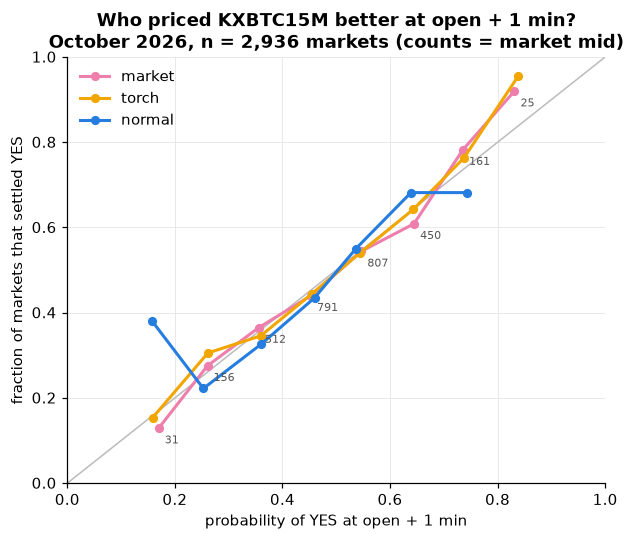

*Bins of width 0.1; bins with fewer than 20 markets are not drawn for any line.*

In [30]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.plot([0, 1], [0, 1], color="#bbb", lw=1)
MIN_BIN = 20
for m in ["market", "torch", "normal"]:
    rel = reliability(KE[m], KE.y); rel = rel[rel.n >= MIN_BIN]
    ax.plot(rel.mean_pred, rel.obs_freq, marker="o", ms=5, color=COLORS[m], label=m)
rel = reliability(KE["market"], KE.y); rel = rel[rel.n >= MIN_BIN]
for _, rr in rel.iterrows():
    ax.annotate(f"{rr.n}", (rr.mean_pred, rr.obs_freq), textcoords="offset points", xytext=(4, -10), fontsize=7, color="#555")
ax.set(xlabel="probability of YES at open + 1 min", ylabel="fraction of markets that settled YES", xlim=(0, 1), ylim=(0, 1),
       title=f"Who priced KXBTC15M better at open + 1 min?\nOctober 2026, n = {len(KE):,} markets (counts = market mid)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
show(f"*Bins of width 0.1; bins with fewer than {MIN_BIN} markets are not drawn for any line.*")

**Where this section ends.** The cached data supports a probability-accuracy comparison: model vs market mid vs actual outcomes on the same markets, at a decision time where both sides know the same things. It does **not** support a profitability claim:
- the 1-minute quote candles give the best bid and ask but no size, so I cannot show a hypothetical order would have filled at the ask;
- I could not retrieve the fee schedule that applied in October 2026 (PDF blocked with HTTP 429; the API only shows the *current* `fee_type`/`fee_multiplier` and an empty change history);
- I have no fills, so no measure of slippage or adverse selection.

So I report no P&L. **Market making** would need full order-book history (depth at each level over time), my own resting-order fills with timestamps, and post-fill price moves to measure adverse selection. None of that is in snapshot quote candles.

## 7. My write-up (blank until I've run it)

**What I saw in the tails, and which observations or counts changed my mind.**
*Look first at:* the tail-count table and exceedance plot (Section 2), the monthly moments table, the list of extreme windows, and the labeled sensitivity row.


**Where the forecasts differed, and whether the held-out scores justified the more complicated model.**
*Look first at:* the strike table with training counts and the worked example (Section 4), the empirical − normal interval plot, and the "comparisons to win" table plus the generated result table (Section 5).


**What I could actually establish about Kalshi from the data I obtained.**
*Look first at:* the contract-terms table, the coverage table, the proxy check, and the market-vs-model score table (Section 6).